In [6]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

df_url = pd.read_csv('Malicious URL Detection.csv')
df_split = pd.read_csv('MURL_Split.csv')

# Pastikan kedua file terbaca utuh (783.705 baris)
print(f"Baris df_url: {len(df_url)} | Baris df_split: {len(df_split)}")
assert len(df_url) == 783705, "File Malicious URL Detection.csv belum terunggah penuh! Tunggu upload selesai lalu ulangi."

df = pd.concat([df_url, df_split['split']], axis=1).dropna()

# Encode 7 label kategori
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['type'])
num_classes = len(le.classes_)
print("Daftar Kelas:", dict(enumerate(le.classes_)))

# Pisahkan data berdasarkan MURL_Split.csv
train_df = df[df['split'] == 'train']
val_df   = df[df['split'] == 'validation']
test_df  = df[df['split'] == 'test']

# Tokenisasi per karakter
MAX_LEN = 200
tokenizer = Tokenizer(char_level=True, lower=False, oov_token='<UNK>')
tokenizer.fit_on_texts(train_df['url'].astype(str))

vocab_size = len(tokenizer.word_index) + 1
print(f"Jumlah karakter unik (vocab_size): {vocab_size}")

X_train = pad_sequences(tokenizer.texts_to_sequences(train_df['url'].astype(str)), maxlen=MAX_LEN, padding='post', truncating='post')
X_val   = pad_sequences(tokenizer.texts_to_sequences(val_df['url'].astype(str)), maxlen=MAX_LEN, padding='post', truncating='post')
X_test  = pad_sequences(tokenizer.texts_to_sequences(test_df['url'].astype(str)), maxlen=MAX_LEN, padding='post', truncating='post')

y_train = train_df['label_encoded'].values
y_val   = val_df['label_encoded'].values
y_test  = test_df['label_encoded'].values

Baris df_url: 783705 | Baris df_split: 783705
Daftar Kelas: {0: 'Exploit', 1: 'benign', 2: 'defacement', 3: 'legitimate', 4: 'malware', 5: 'phishing', 6: 'spam'}
Jumlah karakter unik (vocab_size): 292


Model **Character-Level 1D CNN** (`MAX_LEN = 200`, *smoothed class weight*, 10 epoch) pada dataset **Malicious URL Detection** (`783.705` total data: `548.592` *train*, `117.559` *validation*, dan `117.554` *test*) menghasilkan **Test Accuracy sebesar 79,78%** (`93.781` prediksi benar dari `117.554` data uji), **Weighted F1-Score 80,58%**, dan **Macro F1-Score 62,05%**. Penerapan pembobotan kelas akar kuadrat (*smoothed inverse frequency*) berhasil memulihkan kemampuan model dalam mendeteksi kelas minoritas yang sebelumnya gagal dikenali pada konfigurasi awal tanpa pembobotan.

In [7]:
# 1. Encode 7 label kategori menjadi angka 0 - 6
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['type'])
num_classes = len(le.classes_)
print("Daftar Kelas:", dict(enumerate(le.classes_)))

# 2. Pisahkan data sesuai kolom 'split' dari MURL_Split.csv
train_df = df[df['split'] == 'train']
val_df   = df[df['split'] == 'validation']
test_df  = df[df['split'] == 'test']

# 3. Tokenisasi tingkat karakter (char_level=True) - fit HANYA pada data train
MAX_LEN = 200  # Meng-cover >98% panjang URL tanpa membuang banyak memori
tokenizer = Tokenizer(char_level=True, lower=False, oov_token='<UNK>')
tokenizer.fit_on_texts(train_df['url'].astype(str))

vocab_size = len(tokenizer.word_index) + 1
print(f"Jumlah karakter unik (vocab_size): {vocab_size}")

# Konversi string URL menjadi deretan integer dan samakan panjangnya (padding)
X_train = pad_sequences(tokenizer.texts_to_sequences(train_df['url'].astype(str)), maxlen=MAX_LEN, padding='post', truncating='post')
X_val   = pad_sequences(tokenizer.texts_to_sequences(val_df['url'].astype(str)), maxlen=MAX_LEN, padding='post', truncating='post')
X_test  = pad_sequences(tokenizer.texts_to_sequences(test_df['url'].astype(str)), maxlen=MAX_LEN, padding='post', truncating='post')

y_train = train_df['label_encoded'].values
y_val   = val_df['label_encoded'].values
y_test  = test_df['label_encoded'].values

Daftar Kelas: {0: 'Exploit', 1: 'benign', 2: 'defacement', 3: 'legitimate', 4: 'malware', 5: 'phishing', 6: 'spam'}
Jumlah karakter unik (vocab_size): 292


In [12]:
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=vocab_size, output_dim=32),

    layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(filters=128, kernel_size=5, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.GlobalMaxPooling1D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes)
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 32)        │         9,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 200, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 200, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 100, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 100, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_3          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,823 (292.28 KB)

 Trainable params: 74,439 (290.78 KB)

 Non-trainable params: 384 (1.50 KB)

In [13]:
from sklearn.utils.class_weight import compute_class_weight

# 1. Hitung bobot kelas (smoothed) agar kelas minoritas tetap dipelajari
raw_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(np.power(raw_weights, 0.5)))

# 2. Compile model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# 3. Training
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=512,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)

Epoch 1/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 37s 28ms/step - accuracy: 0.7539 - loss: 0.5542 - val_accuracy: 0.7676 - val_loss: 0.5920
Epoch 2/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.8242 - loss: 0.3814 - val_accuracy: 0.7982 - val_loss: 0.5409
Epoch 3/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.8426 - loss: 0.3330 - val_accuracy: 0.8116 - val_loss: 0.5282
Epoch 4/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.8538 - loss: 0.3058 - val_accuracy: 0.8141 - val_loss: 0.5402
Epoch 5/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.8610 - loss: 0.2837 - val_accuracy: 0.8103 - val_loss: 0.5496
Epoch 6/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 41s 23ms/step - accuracy: 0.8658 - loss: 0.2719 - val_accuracy: 0.8241 - val_loss: 0.5650
Epoch 7/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.8726 - loss: 0.2512 - val_accuracy: 0.8255 - val_loss: 0.5269
Epoch 8/10
1072/1072 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.8752 -

* **Fase Konvergensi Awal (Epoch 1 – 3)**: Model belajar dengan cepat; `accuracy` training naik dari `75,39%` menjadi `84,26%`, diikuti kenaikan `val_accuracy` dari `76,76%` menjadi `81,16%` dan penurunan `val_loss` dari `0,5920` ke `0,5282`.
* **Titik Puncak Generalisasi (Epoch 7)**: Performa validasi terbaik tercapai pada **Epoch 7** dengan `val_accuracy: 82,55%` dan `val_loss` terendah di `0,5269` (saat `accuracy` training berada di `87,26%`).
* **Fase *Overfitting* Ringan (Epoch 8 – 10)**: Setelah Epoch 7, `accuracy` training terus meningkat hingga `87,88%` (`loss: 0,2332`), sedangkan `val_loss` berbalik naik menjadi `0,6282` (Epoch 8) dan berakhir di `0,5980` (Epoch 10) dengan `val_accuracy: 82,11%`. Selisih (*gap*) sebesar **5,77%** antara akurasi training dan validasi di Epoch 10 mengindikasikan model mulai menghafal pola spesifik pada data latih.

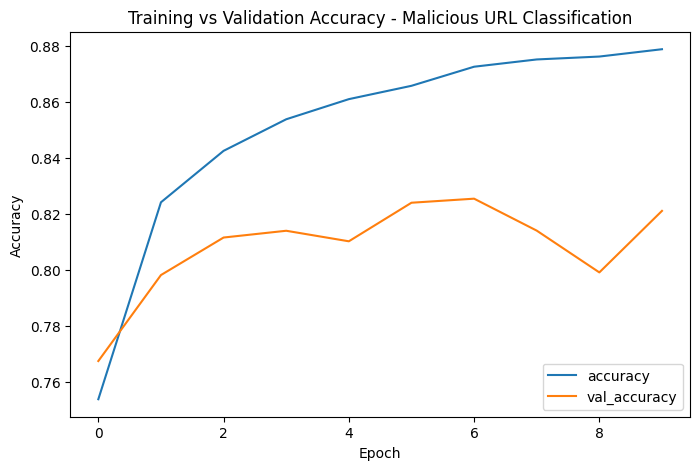

230/230 - 1s - 6ms/step - accuracy: 0.7978 - loss: 0.5760

Test Accuracy: 0.7978 (79.78%)
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step

Classification Report:
              precision    recall  f1-score   support

     Exploit     0.3710    0.6389    0.4694        36
      benign     0.8607    0.8163    0.8379     63969
  defacement     0.9289    0.7789    0.8473     14294
  legitimate     0.1470    0.5791    0.2344       872
     malware     0.9036    0.7929    0.8446      3534
    phishing     0.7103    0.7828    0.7448     34437
        spam     0.4012    0.3350    0.3651       412

    accuracy                         0.7978    117554
   macro avg     0.6175    0.6748    0.6205    117554
weighted avg     0.8192    0.7978    0.8058    117554



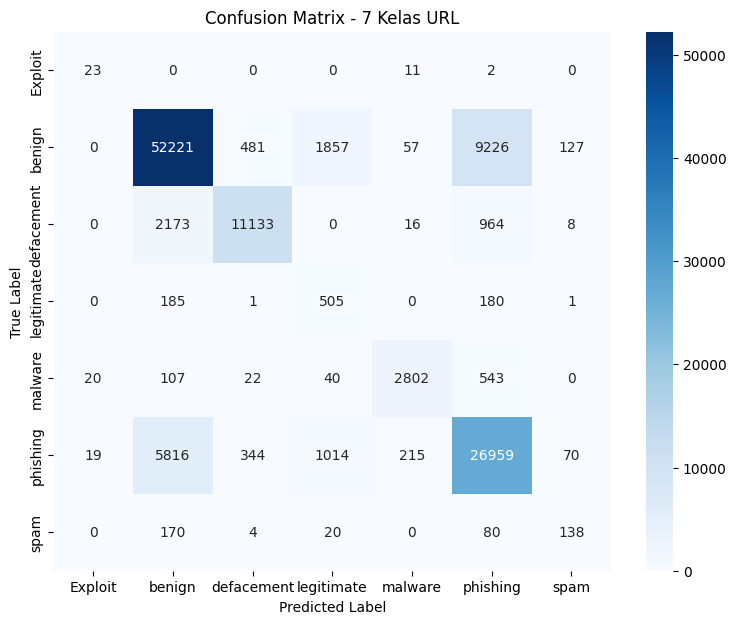

In [14]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Plot Grafik Akurasi & Validasi selama Training
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Training vs Validation Accuracy - Malicious URL Classification')
plt.show()

# 2. Evaluasi Loss & Akurasi pada Test Set (117.554 data uji dari MURL_Split.csv)
test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=512, verbose=2)
print(f"\nTest Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")

# 3. Evaluasi Detail per Kelas (Precision, Recall, F1-Score untuk 7 kelas)
y_pred_logits = model.predict(X_test, batch_size=512)
y_pred = np.argmax(y_pred_logits, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

# 4. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - 7 Kelas URL')
plt.show()

* **Kelompok Kelas dengan Performa Tinggi (`F1 > 83%`)**:
* **`defacement` (F1 `84,73%`)**: Mencatatkan *Precision* tertinggi sebesar `92,89%` dengan `11.133` dari `14.294` sampel uji teridentifikasi benar.


* **`malware` (F1 `84,46%`)**: Mencapai *Precision* `90,36%` dan *Recall* `79,29%` (`2.802` benar dari `3.534` sampel), didukung oleh pola karakter eksplisit seperti alamat IP langsung, nomor port, serta ekstensi biner.


* **`benign` (F1 `83,79%`)**: Sebanyak `52.221` dari `63.969` sampel URL aman terklasifikasi tepat (*Precision* `86,07%`, *Recall* `81,63%`).




* **Kelompok Kelas Menengah (`phishing`, F1 `74,48%`)**:
* Berhasil menangkap `26.959` dari `34.437` sampel (*Recall* `78,28%`, *Precision* `71,03%`).




* **Kelompok Kelas Minoritas (`Exploit`, `spam`, `legitimate`)**:
* **`Exploit` (F1 `46,94%`)**: Dari hanya `36` sampel uji (`170` data latih), model berhasil mengenali `23` sampel (*Recall* `63,89%`), sementara `11` sampel lainnya diprediksi sebagai `malware` akibat kesamaan struktur URL payload biner (`.bin`/`.zip`).


* **`spam` (F1 `36,51%`)**: Mengenali `138` dari `412` sampel uji (*Recall* `33,50%`), sementara `170` sampel masih terbaca sebagai `benign`.


* **`legitimate` (F1 `23,44%`)**: Memiliki *Recall* `57,91%` (`505` dari `872` benar), namun *Precision* tertahan di `14,70%` karena `1.857` sampel `benign` dan `1.014` sampel `phishing` ikut masuk ke kelas ini akibat kesamaan struktur nama domain sah.



Sumber Kesalahan Prediksi Utama

Dari total **23.773 kesalahan prediksi (20,22%)** pada data uji, mayoritas kesalahan terkonsentrasi pada dua pola tumpang tindih berikut:

1. **Friksi `benign` $\leftrightarrow$ `phishing` (`15.042` kasus / 63,27% dari total error)**: Sebanyak `9.226` URL `benign` salah diprediksi sebagai `phishing` dan `5.816` URL `phishing` salah diprediksi sebagai `benign`. Hal ini terjadi karena banyak URL *phishing* menggunakan domain legitim yang diretas (*compromised sites*) atau subfolder panjang sehingga pola urutan karakternya menyerupai URL normal.


2. **Kesalahan `defacement` $\rightarrow$ `benign` (`2.173` kasus / 9,14% dari total error)**: Sebagian URL *defacement* tetap mempertahankan nama domain dan struktur direktori CMS standar sehingga terbaca sebagai tautan aman (`benign`).



Secara keseluruhan, arsitektur Character-Level 1D CNN dengan `MAX_LEN = 200` dan *smoothed class weight* ini sudah memadai sebagai model dasar (*baseline*) klasifikasi URL 7 kelas karena mampu mempertahankan akurasi tinggi pada kelas ancaman utama (`malware`, `defacement`, `phishing`) sekaligus tetap sensitif mendeteksi ancaman langka seperti `Exploit` dan `spam`.